# A/B Test Analysis: One-Page Checkout

**Business question:** ShopNest (a fictional e-commerce site) redesigned its multi-step checkout into a single page. Does the new checkout increase the share of visitors who complete a purchase, and is it safe to roll out to everyone?

| | |
|---|---|
| **Control (A)** | Old multi-step checkout |
| **Treatment (B)** | New one-page checkout |
| **Primary metric** | Conversion rate (purchases / users) |
| **Secondary metrics** | Revenue per user, average order value (AOV) |
| **Test window** | 1–21 Sep 2026 (3 full weeks) |
| **Split** | 50 / 50, randomised at user level |

**Hypotheses** (two-sided, α = 0.05)
- H₀: conversion rate of B = conversion rate of A
- H₁: conversion rate of B ≠ conversion rate of A

*Dataset is synthetic, generated by `generate_data.py`, with real-world logging problems deliberately included.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"control": "#8C8C8C", "treatment": "#2F6FDE"}
ALPHA = 0.05

## 1. Before the test: how many users do we need?

A test has to be sized **before** it starts, otherwise it's tempting to stop the moment the result looks good (a mistake called *peeking*).

Inputs:
- Baseline conversion (from past data): **11.5%**
- Minimum detectable effect (MDE): **+0.8 percentage points** — the smallest lift worth the engineering cost
- Significance level α = 0.05, power = 80%

In [2]:
def sample_size_per_group(p1, mde, alpha=0.05, power=0.80):
    """Users needed in EACH group for a two-sided two-proportion z-test."""
    p2 = p1 + mde
    p_bar = (p1 + p2) / 2
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    z_beta = stats.norm.ppf(power)
    n = (z_alpha * np.sqrt(2 * p_bar * (1 - p_bar))
         + z_beta * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2 / mde ** 2
    return int(np.ceil(n))

n_needed = sample_size_per_group(p1=0.115, mde=0.008)
print(f"Required users per group: {n_needed:,}")
print(f"Required users in total : {2 * n_needed:,}")
print(f"At ~4,300 visitors/day this takes ~{2 * n_needed / 4300:.0f} days; "
      "we ran 21 days to cover 3 full weekly cycles.")

Required users per group: 25,714
Required users in total : 51,428
At ~4,300 visitors/day this takes ~12 days; we ran 21 days to cover 3 full weekly cycles.


## 2. Load and inspect the data

In [3]:
import os
from pathlib import Path

def find_data_file(name="ab_test_data"):
    """Look for the CSV next to the notebook first, then in common Windows folders."""
    for p in [Path("data") / f"{name}.csv", Path(f"{name}.csv")]:
        if p.exists():
            return p
    home = Path.home()
    folders = [home / "Downloads", home / "Desktop", home / "Documents", home / "OneDrive"]
    for folder in folders:
        if folder.exists():
            hits = sorted(folder.rglob(f"{name}*.csv"))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"Could not find {name}.csv. Notebook is running in: {os.getcwd()}")

DATA_PATH = find_data_file()
os.makedirs("images", exist_ok=True)   # charts get saved here
print("Using data file:", DATA_PATH.resolve())

raw = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
print(raw.shape)
raw.head()

Using data file: C:\Users\HP\Downloads\AB Testing\ab_test_data.csv
(92736, 8)


,user_id,timestamp,group,landing_page,device,user_type,converted,revenue
0,143725,2026-09-09 05:22:16,control,old_checkout,desktop,new,0,0.0000
1,190028,2026-09-12 16:05:25,control,old_checkout,desktop,returning,0,0.0000
2,160621,2026-09-08 10:33:00,control,old_checkout,desktop,returning,0,0.0000
3,152602,2026-09-04 16:13:27,control,old_checkout,mobile,returning,0,0.0000
4,178242,2026-09-03 16:55:24,treatment,new_checkout,mobile,new,0,0.0000


In [4]:
raw.info()
print("\nMissing values per column:")
print(raw.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 92736 entries, 0 to 92735
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   user_id       92736 non-null  int64         
 1   timestamp     92736 non-null  datetime64[us]
 2   group         92736 non-null  str           
 3   landing_page  92736 non-null  str           
 4   device        92736 non-null  str           
 5   user_type     92736 non-null  str           
 6   converted     92736 non-null  int64         
 7   revenue       92736 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(2), str(4)
memory usage: 5.7 MB

Missing values per column:
user_id         0
timestamp       0
group           0
landing_page    0
device          0
user_type       0
converted       0
revenue         0
dtype: int64


## 3. Data cleaning

Experiment logs are rarely clean. Three checks:
1. **Exact duplicate rows** (double-logged events)
2. **Group / page mismatch** — user assigned to control but shown the new page (or vice versa)
3. **Users exposed to both versions** — they can't be credited to either group

In [5]:
n_dup = raw.duplicated().sum()
print(f"1) Exact duplicate rows: {n_dup}")

print("\n2) Group vs landing page:")
print(pd.crosstab(raw["group"], raw["landing_page"]))

groups_per_user = raw.groupby("user_id")["group"].nunique()
both_users = groups_per_user[groups_per_user > 1].index
print(f"\n3) Users who saw BOTH versions: {len(both_users)}")

1) Exact duplicate rows: 276

2) Group vs landing page:
landing_page  new_checkout  old_checkout
group                                   
control                401         45739
treatment            46259           337

3) Users who saw BOTH versions: 460


In [6]:
matched = (
    ((raw["group"] == "control") & (raw["landing_page"] == "old_checkout")) |
    ((raw["group"] == "treatment") & (raw["landing_page"] == "new_checkout"))
)

df = (raw.drop_duplicates()
         .loc[matched]
         .loc[lambda d: ~d["user_id"].isin(both_users)]
         .sort_values("timestamp")
         .drop_duplicates("user_id", keep="first")
         .reset_index(drop=True))

removed = raw["user_id"].nunique() - df["user_id"].nunique()
print(f"Rows before: {len(raw):,}  |  users before: {raw['user_id'].nunique():,}")
print(f"Rows after : {len(df):,}  |  users after : {df['user_id'].nunique():,}")
print(f"Users removed: {removed:,} ({removed / raw['user_id'].nunique():.2%})")
assert df["user_id"].is_unique

Rows before: 92,736  |  users before: 92,000
Rows after : 90,805  |  users after : 90,805
Users removed: 1,195 (1.30%)


## 4. Sanity check: Sample Ratio Mismatch (SRM)

We designed a 50/50 split. If the observed split is far from 50/50, randomisation or logging is broken and **no result can be trusted**. A chi-square goodness-of-fit test checks this.

In [7]:
counts = df["group"].value_counts().sort_index()
expected = [counts.sum() / 2] * 2
chi2, p_srm = stats.chisquare(counts, f_exp=expected)

print(counts.to_string())
print(f"\nChi-square = {chi2:.3f}, p-value = {p_srm:.4f}")
print("SRM detected — investigate before analysing!" if p_srm < 0.01
      else "No SRM: the split is consistent with 50/50. Safe to proceed.")

group
control      45147
treatment    45658

Chi-square = 2.876, p-value = 0.0899
No SRM: the split is consistent with 50/50. Safe to proceed.


## 5. Primary metric: conversion rate

In [8]:
summary = df.groupby("group").agg(
    users=("user_id", "count"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean"),
    revenue_per_user=("revenue", "mean"),
)
summary

,users,conversions,conversion_rate,revenue_per_user
group,,,,
control,45147,5180,0.1147,177.6968
treatment,45658,5875,0.1287,201.8431


### Two-proportion z-test

Conversion is a yes/no outcome, so we compare two proportions. The z-test uses the **pooled** rate for the p-value, and the **unpooled** standard error for the confidence interval of the difference.

In [9]:
def two_proportion_ztest(conv_a, n_a, conv_b, n_b, alpha=0.05):
    p_a, p_b = conv_a / n_a, conv_b / n_b
    diff = p_b - p_a

    # hypothesis test (pooled SE)
    p_pool = (conv_a + conv_b) / (n_a + n_b)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
    z = diff / se_pool
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))

    # confidence interval for the difference (unpooled SE)
    se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    z_crit = stats.norm.ppf(1 - alpha / 2)
    ci = (diff - z_crit * se, diff + z_crit * se)

    return {"p_a": p_a, "p_b": p_b, "abs_lift": diff, "rel_lift": diff / p_a,
            "z": z, "p_value": p_value, "ci_low": ci[0], "ci_high": ci[1]}

a, b = summary.loc["control"], summary.loc["treatment"]
res = two_proportion_ztest(a.conversions, a.users, b.conversions, b.users)

print(f"Control conversion   : {res['p_a']:.2%}")
print(f"Treatment conversion : {res['p_b']:.2%}")
print(f"Absolute lift        : {res['abs_lift'] * 100:+.2f} pp")
print(f"Relative lift        : {res['rel_lift']:+.1%}")
print(f"95% CI (absolute)    : [{res['ci_low'] * 100:+.2f} pp, {res['ci_high'] * 100:+.2f} pp]")
print(f"z = {res['z']:.2f},  p-value = {res['p_value']:.2e}")
print("\nResult:", "statistically significant — reject H0" if res["p_value"] < ALPHA
      else "not significant — cannot reject H0")

Control conversion   : 11.47%
Treatment conversion : 12.87%
Absolute lift        : +1.39 pp
Relative lift        : +12.1%
95% CI (absolute)    : [+0.97 pp, +1.82 pp]
z = 6.42,  p-value = 1.34e-10

Result: statistically significant — reject H0


**How to read this:** the p-value is the probability of seeing a gap this large *if the new checkout made no difference*. It's tiny, so chance is a very unlikely explanation. The confidence interval matters more for the business: even its **lower bound** is above the +0.8 pp MDE we said was worth shipping.

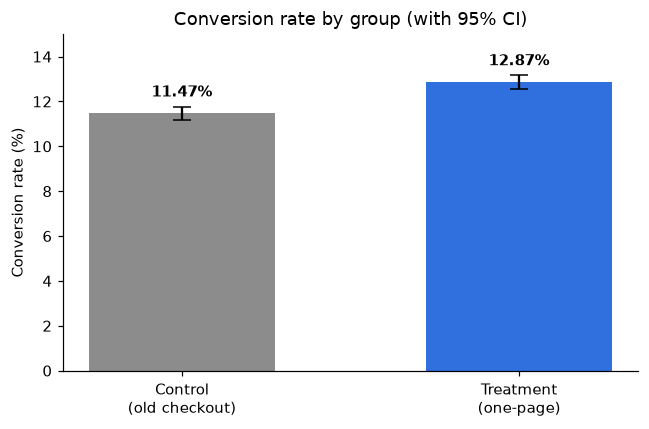

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
rates = [res["p_a"], res["p_b"]]
errs = [stats.norm.ppf(0.975) * np.sqrt(p * (1 - p) / n)
        for p, n in zip(rates, [a.users, b.users])]
bars = ax.bar(["Control\n(old checkout)", "Treatment\n(one-page)"], [r * 100 for r in rates],
              yerr=[e * 100 for e in errs], capsize=6,
              color=[COLORS["control"], COLORS["treatment"]], width=0.55)
for bar, r in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width() / 2, r * 100 + 0.75, f"{r:.2%}",
            ha="center", fontweight="bold")
ax.set_ylabel("Conversion rate (%)")
ax.set_ylim(0, 15)
ax.set_title("Conversion rate by group (with 95% CI)")
plt.tight_layout()
plt.savefig("images/conversion_by_group.png", bbox_inches="tight")
plt.show()

## 6. Secondary metric: revenue per user

Revenue is heavily right-skewed (most users spend ₹0, a few spend a lot), so alongside Welch's t-test we use a **bootstrap** confidence interval, which makes no assumption about the shape of the distribution.

In [11]:
rev_a = df.loc[df["group"] == "control", "revenue"].to_numpy()
rev_b = df.loc[df["group"] == "treatment", "revenue"].to_numpy()

t_stat, p_rev = stats.ttest_ind(rev_b, rev_a, equal_var=False)  # Welch's t-test

rng = np.random.default_rng(0)
boot = np.array([
    rng.choice(rev_b, rev_b.size).mean() - rng.choice(rev_a, rev_a.size).mean()
    for _ in range(2000)
])
ci_rev = np.percentile(boot, [2.5, 97.5])

print(f"Revenue per user — control  : ₹{rev_a.mean():,.2f}")
print(f"Revenue per user — treatment: ₹{rev_b.mean():,.2f}")
print(f"Difference: ₹{rev_b.mean() - rev_a.mean():+,.2f} per user "
      f"({(rev_b.mean() / rev_a.mean() - 1):+.1%})")
print(f"Welch t-test p-value: {p_rev:.2e}")
print(f"Bootstrap 95% CI    : [₹{ci_rev[0]:+,.2f}, ₹{ci_rev[1]:+,.2f}]")

Revenue per user — control  : ₹177.70
Revenue per user — treatment: ₹201.84
Difference: ₹+24.15 per user (+13.6%)
Welch t-test p-value: 1.47e-09
Bootstrap 95% CI    : [₹+16.43, ₹+32.18]


In [12]:
aov = df[df["converted"] == 1].groupby("group")["revenue"]
aov_a, aov_b = aov.get_group("control"), aov.get_group("treatment")
_, p_aov = stats.ttest_ind(aov_b, aov_a, equal_var=False)
print(f"Average order value — control: ₹{aov_a.mean():,.0f}, treatment: ₹{aov_b.mean():,.0f}  "
      f"(p = {p_aov:.2f})")
print("=> Basket size didn't change. The revenue gain comes from MORE buyers, not bigger orders.")

Average order value — control: ₹1,549, treatment: ₹1,569  (p = 0.25)
=> Basket size didn't change. The revenue gain comes from MORE buyers, not bigger orders.


## 7. Segment analysis: who does it work for?

An overall win can hide a segment that is hurt. We check device and user type.

Because we run **4 extra tests**, the chance of a false positive rises. A **Bonferroni correction** divides α by the number of tests: 0.05 / 4 = 0.0125.

In [13]:
rows = []
for col in ["device", "user_type"]:
    for seg, d in df.groupby(col):
        g = d.groupby("group")["converted"].agg(["sum", "count"])
        r = two_proportion_ztest(g.loc["control", "sum"], g.loc["control", "count"],
                                 g.loc["treatment", "sum"], g.loc["treatment", "count"])
        rows.append({"dimension": col, "segment": seg, "users": len(d),
                     "control_cr": r["p_a"], "treatment_cr": r["p_b"],
                     "abs_lift_pp": r["abs_lift"] * 100, "rel_lift": r["rel_lift"],
                     "ci_low_pp": r["ci_low"] * 100, "ci_high_pp": r["ci_high"] * 100,
                     "p_value": r["p_value"]})

seg = pd.DataFrame(rows)
alpha_bonf = ALPHA / len(seg)
seg["significant"] = seg["p_value"] < alpha_bonf
print(f"Bonferroni-adjusted alpha = {alpha_bonf}")
seg

Bonferroni-adjusted alpha = 0.0125


,dimension,segment,users,control_cr,treatment_cr,abs_lift_pp,rel_lift,ci_low_pp,ci_high_pp,p_value,significant
0,device,desktop,34418,0.1348,0.1399,0.5130,0.0381,-0.2143,1.2402,0.1669,False
1,device,mobile,56387,0.1026,0.1218,1.9163,0.1868,1.3957,2.4370,0.0000,True
2,user_type,new,49951,0.0963,0.1124,1.6108,0.1673,1.0749,2.1467,0.0000,True
3,user_type,returning,40854,0.1373,0.1486,1.1273,0.0821,0.4487,1.8059,0.0011,True


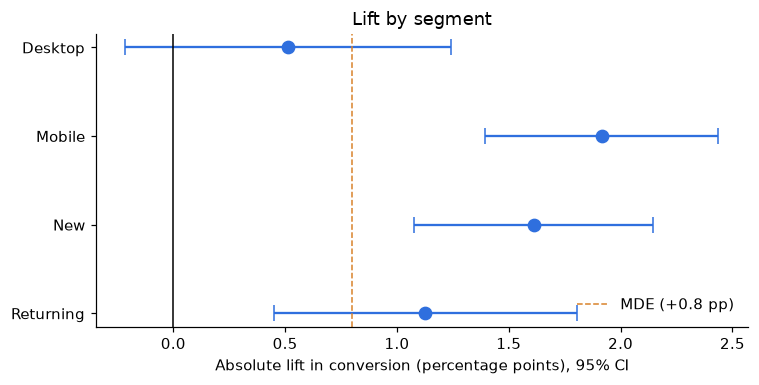

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
labels = seg["segment"].str.capitalize()
y = np.arange(len(seg))[::-1]
ax.errorbar(seg["abs_lift_pp"], y,
            xerr=[seg["abs_lift_pp"] - seg["ci_low_pp"], seg["ci_high_pp"] - seg["abs_lift_pp"]],
            fmt="o", color=COLORS["treatment"], capsize=5, markersize=8)
ax.axvline(0, color="black", lw=1)
ax.axvline(0.8, color="#D9822B", lw=1, ls="--", label="MDE (+0.8 pp)")
ax.set_yticks(y, labels)
ax.set_xlabel("Absolute lift in conversion (percentage points), 95% CI")
ax.set_title("Lift by segment")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.savefig("images/lift_by_segment.png", bbox_inches="tight")
plt.show()

**Insight:** the lift is concentrated on **mobile** (+1.9 pp, about +19% relative). On desktop the effect is small and its confidence interval includes zero — we can't claim it helps desktop users, but there's no sign it hurts them either. That fits the design: collapsing several screens into one helps most on a small screen.

## 8. Is the effect stable over time? (novelty check)

Users sometimes click on anything new for the first few days — a **novelty effect** — and the lift then fades. We compare week 1 with weeks 2–3 and plot the daily rates.

In [15]:
df["date"] = df["timestamp"].dt.date
df["period"] = np.where(df["timestamp"] < "2026-09-08", "week 1", "weeks 2-3")

by_period = df.pivot_table(index="period", columns="group", values="converted", aggfunc="mean")
by_period["abs_lift_pp"] = (by_period["treatment"] - by_period["control"]) * 100
print(by_period.round(4))

group      control  treatment  abs_lift_pp
period                                    
week 1      0.1158     0.1314       1.5613
weeks 2-3   0.1142     0.1273       1.3075


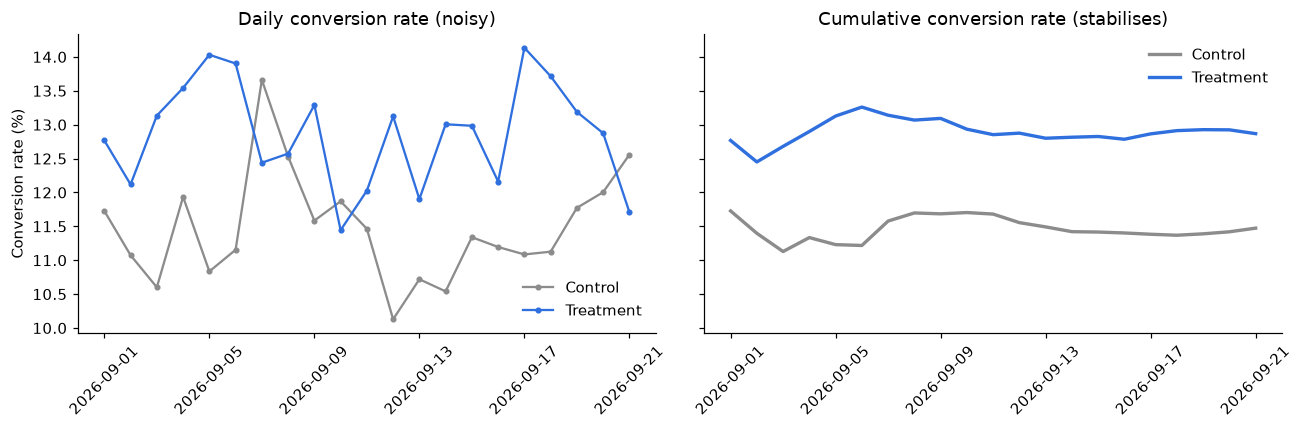

In [16]:
daily = df.pivot_table(index="date", columns="group", values="converted", aggfunc="mean") * 100
cum = (df.sort_values("timestamp")
         .assign(day=lambda d: d["timestamp"].dt.date)
         .groupby(["day", "group"])["converted"].agg(["sum", "count"])
         .groupby(level="group").cumsum())
cum_rate = (cum["sum"] / cum["count"]).unstack() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for g in ["control", "treatment"]:
    axes[0].plot(daily.index, daily[g], marker="o", ms=3, color=COLORS[g], label=g.capitalize())
    axes[1].plot(cum_rate.index, cum_rate[g], lw=2.2, color=COLORS[g], label=g.capitalize())
axes[0].set_title("Daily conversion rate (noisy)")
axes[1].set_title("Cumulative conversion rate (stabilises)")
axes[0].set_ylabel("Conversion rate (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("images/conversion_over_time.png", bbox_inches="tight")
plt.show()

The lift shrinks slightly after week 1 (a small novelty bump), but stays clearly positive through weeks 2–3. The cumulative lines separate early and stay apart — the result isn't a one-off spike.

## 9. Business impact

In [17]:
monthly_visitors = 130_000                      # assumption: ~4,300 visitors/day
lift_low, lift_mid = res["ci_low"], res["abs_lift"]
aov_all = df.loc[df["converted"] == 1, "revenue"].mean()

for name, lift in [("Conservative (CI lower bound)", lift_low), ("Expected (point estimate)", lift_mid)]:
    extra_orders = monthly_visitors * lift
    print(f"{name:32s}: +{extra_orders:,.0f} orders/month  ≈ ₹{extra_orders * aov_all / 1e5:,.1f} lakh/month")

Conservative (CI lower bound)   : +1,259 orders/month  ≈ ₹19.6 lakh/month
Expected (point estimate)       : +1,812 orders/month  ≈ ₹28.3 lakh/month


## 10. Recommendation

| Check | Result |
|---|---|
| Data quality | 1.3% of users removed (mismatched logs, users in both groups, duplicates) |
| Sample ratio | No SRM (split consistent with 50/50) |
| Conversion | **11.47% → 12.87%**, +1.4 pp (+12% relative), p < 0.001 |
| Revenue / user | **+₹24 per user (+14%)**, significant |
| Average order value | Unchanged — the gain comes from more buyers |
| Segments | Strong on mobile; desktop neutral (no harm) |
| Over time | Small novelty bump in week 1, effect holds in weeks 2–3 |

**Decision: roll out the one-page checkout to 100% of users.**

Next steps:
1. Keep a 5% holdout for 4 weeks to confirm the long-run effect.
2. Investigate why desktop gains are small (e.g. a follow-up test on desktop layout).
3. Monitor guardrail metrics after launch: payment failure rate, refund rate, page-load time.

**Limitations:** synthetic data; one test window (no festive-season traffic); revenue measured at order time, so refunds and returns aren't captured.